# Vision classique : seuillage, blobs, piece de reference, mesure

Sans apprentissage, et pourtant souvent suffisant quand le contraste est franc ou les pieces
identiques. Dans tous les cas, c'est la base de comparaison qu'un modele appris doit battre.
Le notebook se lance depuis la racine du depot.

In [1]:
import json  # json : relit les resultats metrics.json ecrits par le script baseline.py
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images (ici : dessiner des formes)
import matplotlib.pyplot as plt  # matplotlib : trace les figures
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)

# seuillage, mesure des taches (blobs), filtrage et dessin des taches, comparaison a une reference, mesure de bords
from vtb.classical import blob_table, compare_to_reference, draw_blobs, filter_blobs, strip_width, strongest_edge, threshold
from vtb.classical.baseline import build_reference  # piece de reference : mediane pixel a pixel d'images normales
from vtb.core.config import DataConfig  # decrit ou sont les donnees et comment elles sont rangees
from vtb.io.catalogs import build_catalog  # liste les images du jeu dans un tableau (le catalogue)
from vtb.io.images import read_image, read_mask  # lecture d'une image et d'un masque de defaut (tableau de 0 et de 1)
from vtb.preprocess import Pipeline  # enchaine des operations de pretraitement nommees

plt.rcParams["figure.dpi"] = 72  # figures plus legeres dans le .ipynb enregistre
try:  # figures en JPEG dans le notebook : 4 a 5 fois plus legeres que le PNG pour des photos
    from matplotlib_inline.backend_inline import set_matplotlib_formats  # reglage du format des figures dans Jupyter

    set_matplotlib_formats("jpeg")  # les figures affichees seront encodees en JPEG
except ImportError:  # si ce module n'est pas installe (hors Jupyter)
    pass  # on ne fait rien : les figures restent en PNG

## 1. Seuillage : quatre methodes sur une carte de reponse

Sur une tuile magnetique, on fabrique d'abord une carte ou les defauts sombres ressortent
(median, correction d'illumination, black-hat), puis on la seuille. Otsu et triangle choisissent
le seuil image par image ; en production on prefere un seuil fixe regle sur la validation.

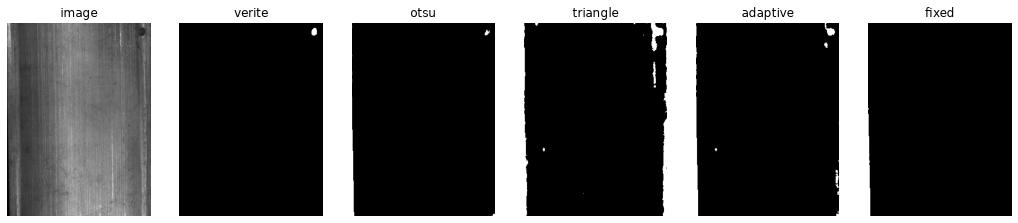

In [2]:
tile_path = sorted(Path("data/raw/magnetic_tile/MT_Blowhole/Imgs").glob("*.jpg"))[3]  # 4e image de tuile avec soufflure
tile = read_image(tile_path, color="gray")  # l'image en niveaux de gris
truth = read_mask(tile_path.with_suffix(".png"))  # son masque de verite (meme nom, extension .png)
response = Pipeline(  # pretraitement en 3 operations, appliquees dans l'ordre ; (tile) a la fin l'applique a l'image
    [  # liste des operations : chacune est un dict {"name": nom, autres cles: reglages}
        {"name": "median_blur", "ksize": 7},  # filtre median 7 x 7 : enleve le bruit fin en gardant les bords nets
        # divise l'image par son fond tres flou : corrige un eclairage inegal (downscale=2 : calcul plus rapide)
        {"name": "shading_division", "sigma": 30, "downscale": 2},
        {"name": "blackhat", "kernel": 21},  # black-hat : ne garde que les petits objets SOMBRES, rendus en clair
    ]
)(tile)  # applique les 3 operations a la tuile : on obtient la carte de reponse (defauts en clair)
# un masque par methode de seuillage : otsu et triangle choisissent le seuil seuls, adaptive = seuil local, fixed = value
masks = {m: threshold(response, method=m, value=40, block_size=51, c=-10) for m in ("otsu", "triangle", "adaptive", "fixed")}
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))  # 6 cases : image, verite, puis les 4 masques
for ax, (name, img) in zip(axes, [("image", tile), ("verite", truth), *masks.items()]):  # pour chaque case et (titre, image)
    ax.imshow(img, cmap="gray")  # affiche en niveaux de gris
    ax.set_title(name)  # titre de la case
    ax.axis("off")  # masque les axes gradues
plt.show()  # affiche la figure

## 2. Analyse de blobs : distinguer une piqure d'une rayure par la forme

Chaque tache est mesuree ; on filtre ensuite sur l'aire, l'elongation, la circularite.

,id,x,y,width,height,area,cx,cy,perimeter,circularity,elongation,angle,mean_intensity,max_intensity
0,1,89,19,43,53,217,110.0,45.0,139.97,0.14,20.22,51.37,220.0,220.0
1,2,168,28,25,25,441,180.0,40.0,77.25,0.93,1.00,0.00,220.0,220.0
2,3,31,31,19,19,253,40.0,40.0,57.94,0.95,1.00,0.00,220.0,220.0
3,4,115,95,11,11,81,120.0,100.0,32.97,0.94,1.00,0.00,220.0,220.0
4,5,19,109,183,18,530,110.0,117.5,378.08,0.05,62.90,4.77,220.0,220.0


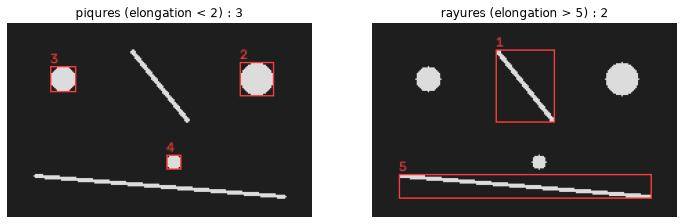

In [3]:
shapes = np.full((140, 220), 30, np.uint8)  # image synthetique 140 x 220, fond gris sombre (valeur 30)
for center, radius in (((40, 40), 9), ((120, 100), 5), ((180, 40), 12)):  # pour 3 disques (centre (x, y), rayon)
    cv2.circle(shapes, center, radius, 220, -1)  # dessine un disque clair (220) ; -1 = rempli : une "piqure"
cv2.line(shapes, (20, 110), (200, 125), 220, 2)  # trait fin et long (epaisseur 2) : une "rayure"
cv2.line(shapes, (90, 20), (130, 70), 220, 2)  # une seconde rayure, plus courte
# blob = tache de pixels voisins ; seuillage puis une ligne par tache : aire, elongation, circularite...
table = blob_table(threshold(shapes), shapes)
display(table.round(2))  # noqa: F821  (display existe dans Jupyter) affiche le tableau arrondi a 2 decimales
# elongation = longueur / largeur de la tache : < 2 = ronde (piqure), > 5 = allongee (rayure)
pits, scratches = filter_blobs(table, max_elongation=2.0), filter_blobs(table, min_elongation=5.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 2 cases cote a cote
axes[0].imshow(draw_blobs(shapes, pits))  # 1re case : les piqures encadrees
axes[0].set_title(f"piqures (elongation < 2) : {len(pits)}")  # titre avec leur nombre
axes[1].imshow(draw_blobs(shapes, scratches))  # 2e case : les rayures encadrees
axes[1].set_title(f"rayures (elongation > 5) : {len(scratches)}")  # titre avec leur nombre
for ax in axes:  # pour chaque case
    ax.axis("off")  # masque les axes gradues
plt.show()  # affiche la figure

## 3. Comparaison a une piece de reference (MVTec bottle)

La reference est la mediane de 60 bouteilles normales (la mediane ignore un defaut qui serait
present sur une seule image). Chaque image est alignee (ECC) puis soustraite.

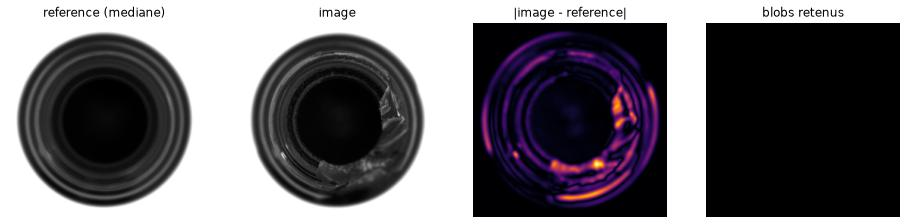

,id,x,y,width,height,area,cx,cy,perimeter,circularity,elongation,angle,mean_intensity,max_intensity


In [4]:
catalog = build_catalog(DataConfig(root="data/raw/mvtec_bottle", layout="mvtec"))  # catalogue des bouteilles (rangement MVTec)
scale = Pipeline([{"name": "resize", "size": 256}])  # pretraitement unique : redimensionner a 256 x 256
# reference = mediane pixel a pixel des 60 premieres bouteilles de train (toutes normales), en niveaux de gris
reference = build_reference(catalog[catalog["split"] == "train"]["path"].head(60).tolist(), scale, "gray")
defect_row = catalog[catalog["defect_type"] == "broken_large"].iloc[0]  # 1re bouteille au goulot casse
image = scale(read_image(defect_row["path"], color="gray"))  # la lit en gris et la redimensionne comme la reference
# aligne l'image sur la reference (ECC : recalage automatique), lisse, soustrait, seuille a 0,25, garde les taches >= 60 px
result = compare_to_reference(image, reference, align="ecc", blur_sigma=2.0, threshold=0.25, min_area=60)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))  # 4 cases cote a cote
for ax, (name, img) in zip(  # pour chaque case et chaque couple (titre, image)
    axes,  # les 4 cases
    [  # couples (titre, image) a afficher
        ("reference (mediane)", reference),  # la piece de reference
        ("image", image),  # la bouteille a controler
        ("|image - reference|", result["diff"]),  # ecart absolu pixel a pixel (clair = different)
        ("blobs retenus", result["mask"]),  # taches assez grandes et assez fortes = defauts detectes
    ],
):
    ax.imshow(img, cmap="gray" if name != "|image - reference|" else "inferno")  # palette de couleurs pour l'ecart, gris sinon
    ax.set_title(name)  # titre de la case
    ax.axis("off")  # masque les axes gradues
plt.show()  # affiche la figure
result["blobs"].round(2)  # derniere ligne de la cellule : le notebook affiche le tableau des taches trouvees

## 4. Resultats des deux bases de comparaison

Seuil et aire minimale choisis sur la validation, test lu une fois (`scripts/baseline.py`).
La comparaison a une reference marche correctement sur des bouteilles identiques et centrees ;
le seuillage d'une carte de reponse echoue sur une surface texturee (Magnetic Tile) : la
texture repond autant que les defauts.

In [5]:
for name in ("mvtec_bottle_reference", "magnetic_tile"):  # pour chacune des deux experiences du script baseline.py
    path = Path("outputs/classical") / name / "metrics.json"  # fichier de mesures de cette experience
    if path.exists():  # si l'experience a deja ete lancee
        metrics = json.loads(path.read_text())  # relit les mesures (dict)
        print(  # une ligne de resultats : nom (sur 24 caracteres), IoU, Dice, rappel, fausses alarmes
            f"{name:24s} IoU {metrics['iou']:.3f} | Dice {metrics['dice']:.3f} | rappel {metrics['recall']:.3f} | fausses alarmes {metrics['false_alarm_rate']:.3f}"
        )
    else:  # sinon : l'experience n'a pas encore ete lancee
        # rappelle la commande a lancer pour produire ses resultats
        print(f"{name} : lancer python recipes/classical/scripts/baseline.py --config recipes/classical/configs/{name}.yaml")

mvtec_bottle_reference   IoU 0.044 | Dice 0.084 | rappel 0.605 | fausses alarmes 0.000
magnetic_tile            IoU 0.058 | Dice 0.109 | rappel 1.000 | fausses alarmes 1.000


## 5. Mesure au sous-pixel

Le bord est au maximum de la derivee du profil lisse ; l'interpolation parabolique autour de ce
maximum donne sa position a quelques centiemes de pixel. La largeur d'une bande se mesure ainsi
ligne par ligne ; multipliee par l'echelle (mm / pixel, calibration), elle donne des millimetres.

bord reel 33.37 px | bord trouve 33.31 px | ecart -0.065 px
largeur : 180.710 px +/- 0.095 -> 45.177 mm (vraie : 45.188 mm)


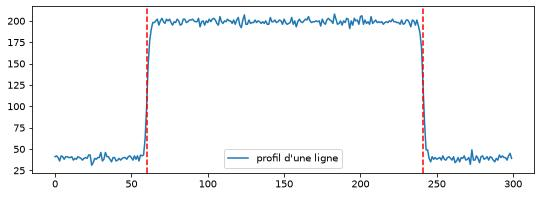

In [6]:
x = np.arange(80, dtype=float)  # positions 0 a 79 le long d'une ligne de pixels
true_edge = 33.37  # vraie position du bord, entre deux pixels
# profil synthetique : passage de 40 a 190 en douceur (sigmoide) autour du bord, plus un leger bruit aleatoire
profile = 40 + 150 / (1 + np.exp(-(x - true_edge) / 0.9)) + np.random.default_rng(0).normal(0, 2, x.size)
found = strongest_edge(profile, "rising", smooth_sigma=1.0)  # position estimee du bord montant (sombre -> clair), au sous-pixel
print(f"bord reel {true_edge:.2f} px | bord trouve {found:.2f} px | ecart {found - true_edge:+.3f} px")  # compare au vrai bord
cols = np.arange(300, dtype=float)  # positions 0 a 299 le long d'une ligne
# profil d'une bande claire : monte vers 60,4 px, redescend vers 241,15 px (largeur vraie : 180,75 px)
band = 40 + 160 / (1 + np.exp(-(cols - 60.4) / 0.8)) - 160 / (1 + np.exp(-(cols - 241.15) / 0.8))
# image de 40 lignes identiques + bruit, bornee a 0-255 et convertie en 8 bits
strip = np.clip(np.tile(band, (40, 1)) + np.random.default_rng(1).normal(0, 3, (40, 300)), 0, 255).astype(np.uint8)
widths = strip_width(strip)  # mesure ligne par ligne : bord gauche, bord droit, largeur en pixels
mm_per_pixel = 0.25  # echelle supposee (normalement donnee par la calibration)
print(  # largeur moyenne +/- ecart-type en pixels, convertie en mm, et la vraie valeur pour comparer
    f"largeur : {widths['width'].mean():.3f} px +/- {widths['width'].std():.3f} -> {widths['width'].mean() * mm_per_pixel:.3f} mm (vraie : {(241.15 - 60.4) * mm_per_pixel:.3f} mm)"
)
plt.figure(figsize=(9, 3))  # nouvelle figure large et basse
plt.plot(strip[0], label="profil d'une ligne")  # trace l'intensite de la 1re ligne de l'image
for edge in (widths["left"].mean(), widths["right"].mean()):  # pour le bord gauche moyen et le bord droit moyen
    plt.axvline(edge, color="red", ls="--")  # trait vertical rouge en pointilles a la position du bord
plt.legend()  # affiche la legende
plt.show()  # affiche la figure